# Линейная регрессия

Автор: Максим Банцевич. CC BY 4.0.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})

## 1. Прямая и её ошибка

Начнём с пяти объектов. У каждого есть один признак `x` и известный ответ `y`. Построим точки и попробуем предсказать ответы прямой.

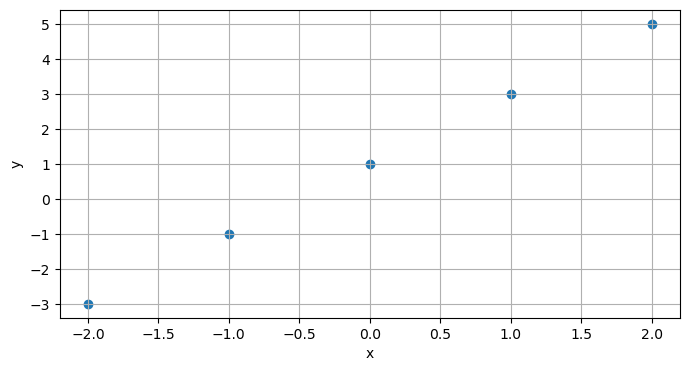

In [2]:
x = np.array([-2., -1., 0., 1., 2.])
y = np.array([-3., -1., 1., 3., 5.])

plt.scatter(x, y)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Прямая задаётся двумя числами: наклоном $w$ и свободным коэффициентом $b$.

$$\hat y = wx+b.$$

Пока выберем их вручную: $w=1$, $b=0$. В NumPy можно сразу получить прогноз для всех объектов.

Ответы:   [-3. -1.  1.  3.  5.]
Прогнозы: [-2. -1.  0.  1.  2.]


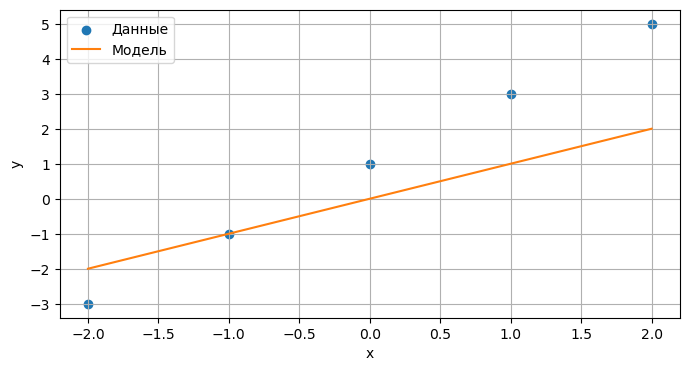

In [3]:
def predict(x, w, b):
    return w * x + b

w, b = 1., 0.
y_pred = predict(x, w, b)
print("Ответы:  ", y)
print("Прогнозы:", y_pred)

plt.scatter(x, y, label="Данные")
plt.plot(x, y_pred, color="tab:orange", label="Модель")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

Оценим качество одним числом — средней квадратичной ошибкой:

$$\operatorname{MSE}=\frac1n\sum_{i=1}^{n}(\hat y_i-y_i)^2.$$

Сначала вычитаем ответы, затем возводим разности в квадрат и берём среднее. Меняйте `w` и `b` в предыдущей ячейке и смотрите, как меняются прямая и ошибка.

In [5]:
def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

print("MSE:", mse(y, predict(x, w, b)))

MSE: 3.0


### Один шаг обучения

Вместо ручного подбора посчитаем, как изменить параметры. Для текущих ошибок $e_i=wx_i+b-y_i$:

$$g_w=2\operatorname{mean}(x_i e_i),\qquad g_b=2\operatorname{mean}(e_i).$$

Вычисляем **обе** производные, затем обновляем параметры: $w\leftarrow w-\eta g_w$, $b\leftarrow b-\eta g_b$.

In [6]:
learning_rate = 0.1
errors = predict(x, w, b) - y
gw = 2 * np.mean(x * errors)
gb = 2 * np.mean(errors)

loss_before = mse(y, predict(x, w, b))
w = w - learning_rate * gw
b = b - learning_rate * gb
loss_after = mse(y, predict(x, w, b))

print(f"w = {w:.3f}, b = {b:.3f}")
print(f"MSE: {loss_before:.3f} → {loss_after:.3f}")

w = 1.400, b = 0.200
MSE: 3.000 → 1.360


## 2. Кто-то пойдёт кодить

Один участник пишет функцию, остальные помогают собрать алгоритм. Функция должна обучать прямую на переданных ей `x` и `y`.

Начните с нулевых параметров, сохраните начальную MSE, затем повторите уже написанный шаг `n_iter` раз. После каждого обновления добавляйте MSE в список. Верните вес, свободный коэффициент и историю ошибки.

In [37]:
def train_line(x, y, learning_rate=0.1, n_iter=200):
    # 1. Создайте w, b и history с начальной ошибкой.
    # 2. В цикле вычисляйте errors, gw и gb.
    # 3. Обновляйте оба параметра и дополняйте history.
    # 4. Верните w, b, history.
    w = np.random.rand()
    b = np.random.rand()
    history = []
    for _ in range(n_iter):
        errors = predict(x, w, b) - y
        gw = 2 * np.mean(x * errors)
        gb = 2 * np.mean(errors)
        w = w - learning_rate * gw
        b = b - learning_rate * gb
        history.append(np.mean(errors))
    return w,b,history
    raise NotImplementedError("Допишите цикл обучения вместе")

w = 2.000, b = 1.000
MSE: -0.363 → -0.000000


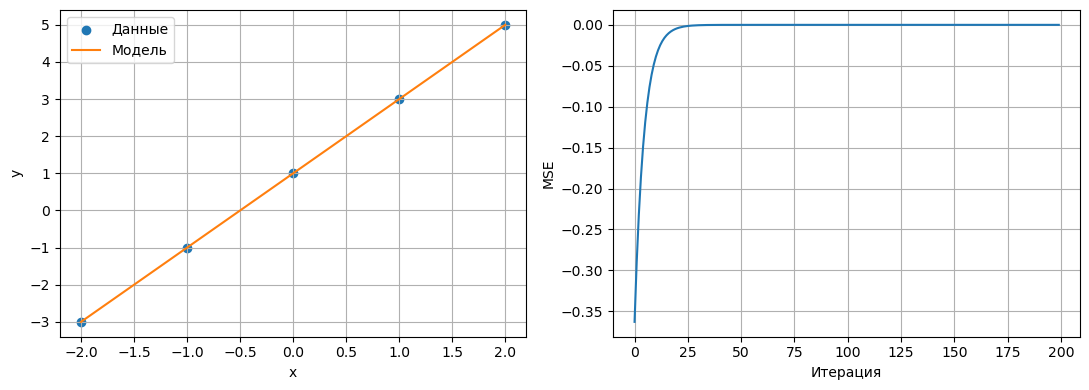

In [38]:
w_fit, b_fit, history = train_line(x, y)
print(f"w = {w_fit:.3f}, b = {b_fit:.3f}")
print(f"MSE: {history[0]:.3f} → {history[-1]:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, y, label="Данные")
axes[0].plot(x, predict(x, w_fit, b_fit), color="tab:orange", label="Модель")
axes[0].set(xlabel="x", ylabel="y")
axes[0].legend()
axes[1].plot(history)
axes[1].set(xlabel="Итерация", ylabel="MSE")
plt.tight_layout()
plt.show()

Для этих точек должны получиться $wpprox2$, $bpprox1$ и MSE, близкая к нулю. Измените число итераций и посмотрите, как прямая приближается к точкам.

## 3. Работаем самостоятельно

Теперь у каждого свой код. Используйте функции `predict`, `mse` и `train_line`, которые мы написали вместе. Новые точки уже подготовлены.

In [ ]:
x_task = np.array([-3., -2., -1., 0., 1., 2., 3.])
y_task = np.array([-4.2, -2.9, -0.8, 0.7, 2.1, 4.0, 5.4])
x_new = np.array([-1.5, 2.5])

### А. Обучите модель и получите прогнозы

Обучите прямую с шагом `0.05` за `300` итераций. Сохраните параметры в `w_task`, `b_task`, историю — в `history_task`. Выведите параметры, итоговую MSE и прогнозы для `x_new`.

Сравните MSE с простым правилом: всем объектам предсказывать среднее значение `y_task`. Среднее считайте по известным ответам; ответов для `x_new` у нас нет.

In [ ]:
# Обучите модель и выведите результаты.
# Для постоянного прогноза пригодятся np.mean и np.full_like.

### Б. Постройте два графика

На первом покажите точки и обученную прямую. На втором — MSE по итерациям. Подпишите оси и добавьте легенду к первому графику.

Для прямой используйте `grid = np.linspace(x_task.min(), x_task.max(), 100)` и посчитайте прогнозы в точках `grid`.

In [ ]:
# Постройте точки и прямую, затем историю ошибки.

### В. Сравните шаги обучения

Обучите три модели: с шагами `0.001`, `0.05`, `0.3`. Для каждой выполните **40 итераций** и сохраните историю MSE.

Постройте три истории на одном графике, подпишите шаги в легенде. Удобно использовать `plt.semilogy`: ошибки сильно различаются по величине.

По графику определите, какой шаг за это время уменьшает ошибку слишком медленно, какой приводит к малой ошибке, а какой вызывает её рост. Объясните результат преподавателю, показав код и графики.

In [ ]:
rates = [0.001, 0.05, 0.3]

# Переберите rates в цикле, вызовите train_line и постройте истории.
# Начинайте каждое обучение заново; число итераций везде равно 40.